# 02 · Onboarding funnel and retention

**Synthetic study.** Which stage loses customers, how quickly do they progress, and how do descriptive return patterns vary?

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import polars as pl
from IPython.display import display, Markdown, Image
ROOT = Path.cwd() if (Path.cwd() / "config/simulation.yaml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.common import config
pl.Config.set_tbl_rows(16)
pl.Config.set_tbl_cols(14)
print("Polars:", pl.__version__)


Polars: 2.0.0


In [2]:
from src.build_database import connect,build
from src.build_metrics import build as build_metrics
if not (ROOT/'data/processed/banking.duckdb').exists():
    build();build_metrics()
con=connect(read_only=True)
metrics=pl.read_parquet(ROOT/'data/processed/user_metrics.parquet')
display(metrics.select('user_id','variant','verified_7d','funded_7d','activated_7d').head())

user_id,variant,verified_7d,funded_7d,activated_7d
i64,str,i32,i32,i32
22067,"""control""",1,1,1
18441,"""control""",1,1,1
17542,"""control""",1,1,1
16612,"""control""",1,1,1
18036,"""control""",1,1,1


## 1. Define the common seven-day denominator
All assigned users with full follow-up remain in the denominator, even if they never verify or fund.

In [3]:
display(metrics.group_by('variant').agg(pl.len().alias('assigned'),pl.col('mature_7d').sum().alias('eligible_7d'),pl.col('mature_30d').sum().alias('eligible_30d')))

variant,assigned,eligible_7d,eligible_30d
str,u32,u32,u32
"""treatment""",125098,125098,125098
"""control""",124902,124902,124902


## 2. SQL funnel with window functions
The previous-step conversion uses `LAG`; overall conversion uses the first step. Read the source SQL before running it.

In [4]:
query=(ROOT/'sql/03_onboarding_funnel.sql').read_text(); print(query); funnel=con.execute(query).pl(); display(funnel)

-- All steps use the same seven-day observation window and assignment denominator.
WITH counts AS (
 SELECT variant,1 AS step_order,'Assigned' AS step,count(*) AS users FROM user_metrics WHERE mature_7d GROUP BY variant
 UNION ALL SELECT variant,2,'Verified',sum(verified_7d) FROM user_metrics WHERE mature_7d GROUP BY variant
 UNION ALL SELECT variant,3,'Funded',sum(funded_7d) FROM user_metrics WHERE mature_7d GROUP BY variant
 UNION ALL SELECT variant,4,'First payment',sum(activated_7d) FROM user_metrics WHERE mature_7d GROUP BY variant
)
SELECT *, users::DOUBLE / first_value(users) OVER(PARTITION BY variant ORDER BY step_order) AS overall_conversion,
 users::DOUBLE / lag(users) OVER(PARTITION BY variant ORDER BY step_order) AS step_conversion
FROM counts ORDER BY variant,step_order;



variant,step_order,step,users,overall_conversion,step_conversion
str,i32,str,"decimal[38,0]",f64,f64
"""control""",1,"""Assigned""",124902,1.0,null
"""control""",2,"""Verified""",92687,0.742078,0.742078
"""control""",3,"""Funded""",73333,0.587124,0.79119
"""control""",4,"""First payment""",60496,0.484348,0.824949
"""treatment""",1,"""Assigned""",125098,1.0,null
"""treatment""",2,"""Verified""",97467,0.779125,0.779125
"""treatment""",3,"""Funded""",79240,0.633423,0.812993
"""treatment""",4,"""First payment""",65440,0.52311,0.825846


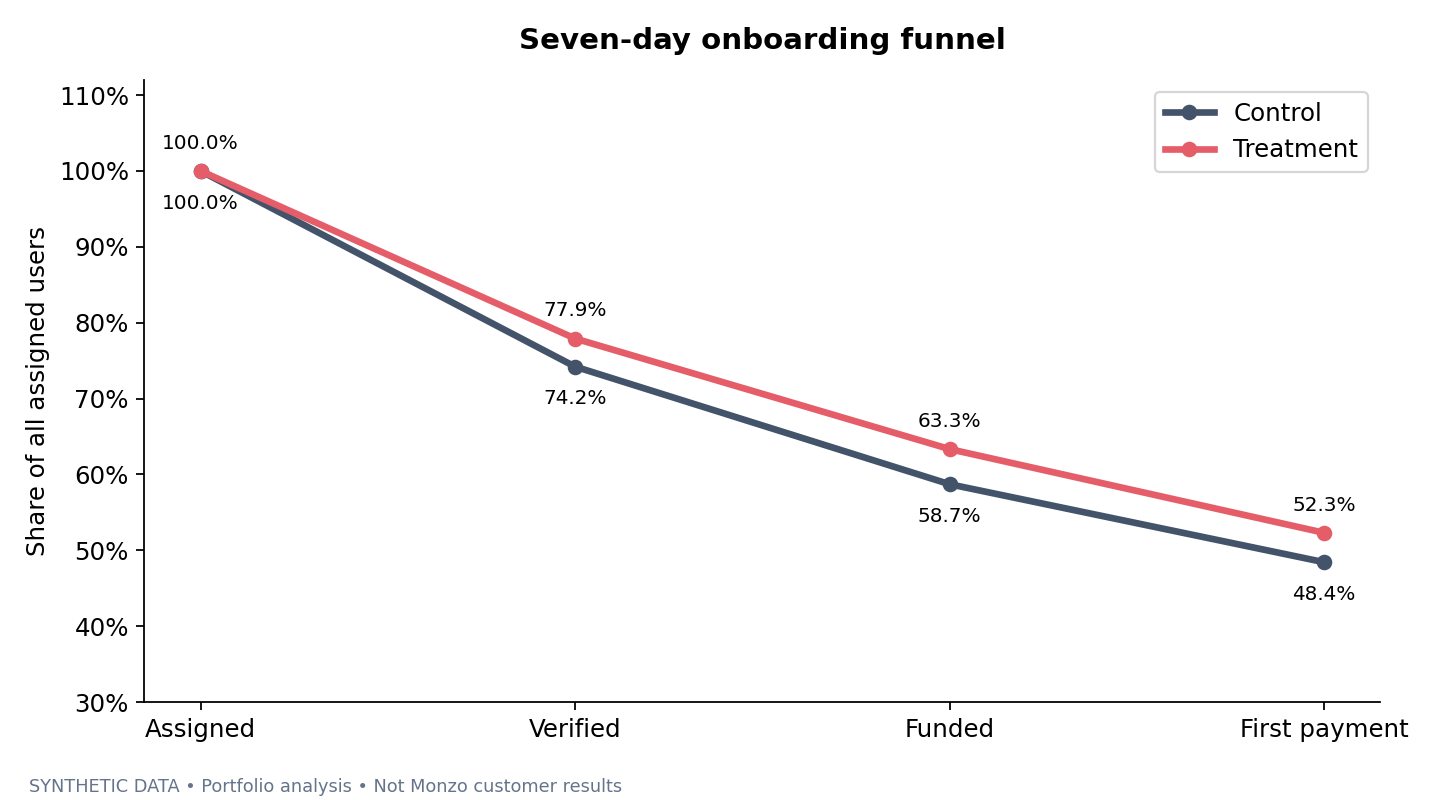

In [5]:
display(Image(filename=str(ROOT/'reports/figures/01_funnel.png')))

## 3. Absolute drop-off counts
A large drop-off stage is a place to investigate. It does not prove the cause or guarantee that optimising it improves business value.

In [6]:
display(funnel.with_columns((pl.col('users').shift(1).over('variant')-pl.col('users')).alias('lost_from_previous_step')))

variant,step_order,step,users,overall_conversion,step_conversion,lost_from_previous_step
str,i32,str,"decimal[38,0]",f64,f64,"decimal[38,0]"
"""control""",1,"""Assigned""",124902,1.0,null,null
"""control""",2,"""Verified""",92687,0.742078,0.742078,32215
"""control""",3,"""Funded""",73333,0.587124,0.79119,19354
"""control""",4,"""First payment""",60496,0.484348,0.824949,12837
"""treatment""",1,"""Assigned""",125098,1.0,null,null
"""treatment""",2,"""Verified""",97467,0.779125,0.779125,27631
"""treatment""",3,"""Funded""",79240,0.633423,0.812993,18227
"""treatment""",4,"""First payment""",65440,0.52311,0.825846,13800


## 4. Time between stages
These medians are conditional on reaching each stage and are descriptive. They are not causal comparisons between equivalent populations.

In [7]:
display(metrics.group_by('variant').agg(
    ((pl.col('verified_at')-pl.col('assigned_at')).dt.total_seconds()/3600).median().alias('median_hours_to_verification_completers'),
    ((pl.col('funded_at')-pl.col('verified_at')).dt.total_seconds()/3600).median().alias('median_hours_verification_to_funding'),
    ((pl.col('first_payment_at')-pl.col('funded_at')).dt.total_seconds()/3600).median().alias('median_hours_funding_to_payment')))

variant,median_hours_to_verification_completers,median_hours_verification_to_funding,median_hours_funding_to_payment
str,f64,f64,f64
"""control""",4.992222,19.951111,24.834583
"""treatment""",4.229167,19.988056,25.000278


## 5. Cumulative activation with all assigned users
This plot keeps non-activators in the denominator. It is preferable to comparing only the average time among users who activated.

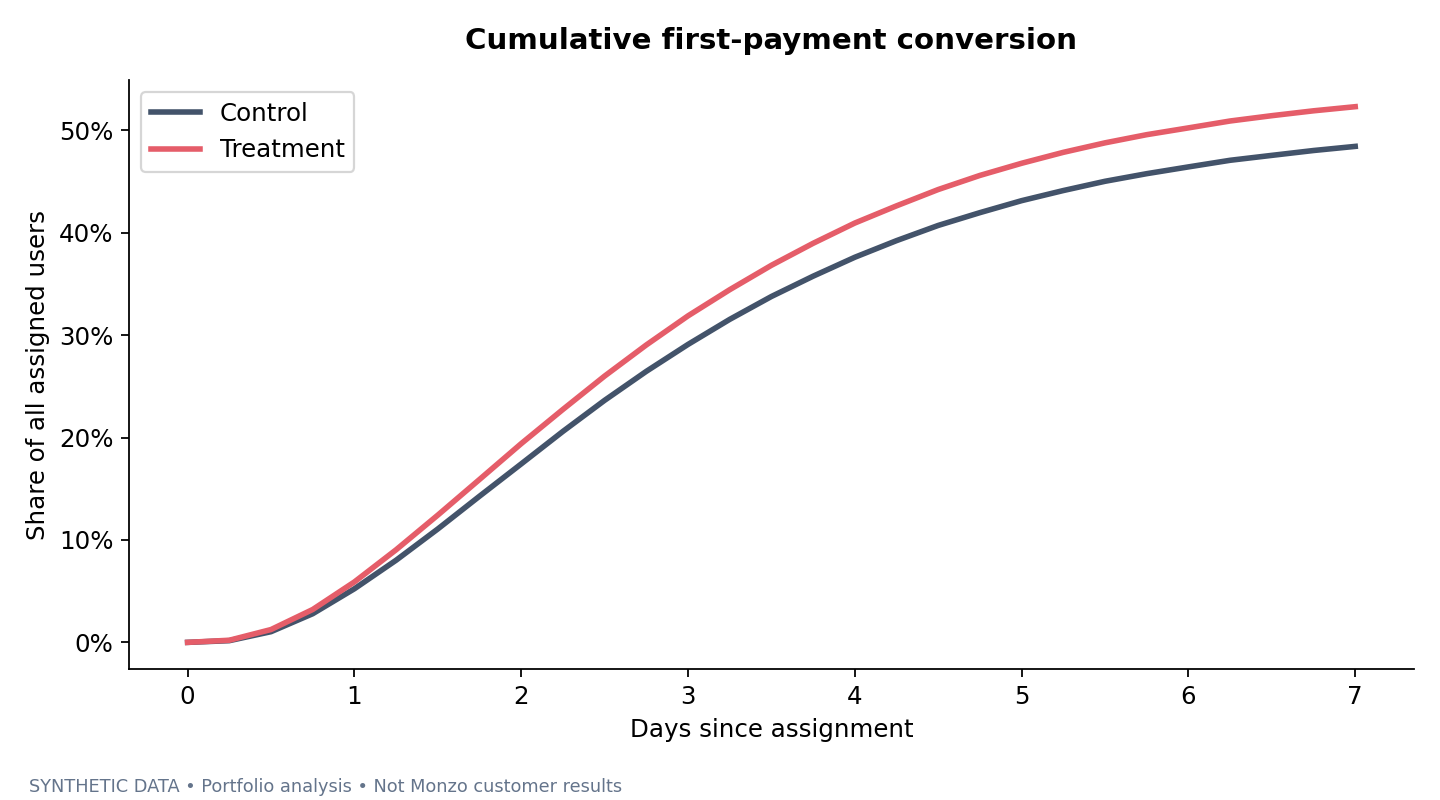

In [8]:
display(Image(filename=str(ROOT/'reports/figures/06_time_to_activation.png')))

## 6. Channel and device cuts
These are exploratory estimates, not a formal treatment-interaction test.

dimension,segment,variant,users,activated,activation_rate
str,str,str,i64,"decimal[38,0]",f64
"""channel""","""referral""","""control""",27464,14924,0.543402
"""channel""","""social""","""treatment""",20052,8801,0.438909
"""channel""","""referral""","""treatment""",27438,16013,0.583607
"""channel""","""social""","""control""",19960,8184,0.41002
"""channel""","""organic""","""treatment""",42228,22010,0.521218
"""channel""","""paid_search""","""treatment""",35380,18616,0.526173
"""channel""","""organic""","""control""",42358,20469,0.483238
"""channel""","""paid_search""","""control""",35120,16919,0.481748
"""device""","""iOS""","""control""",53886,26744,0.496307


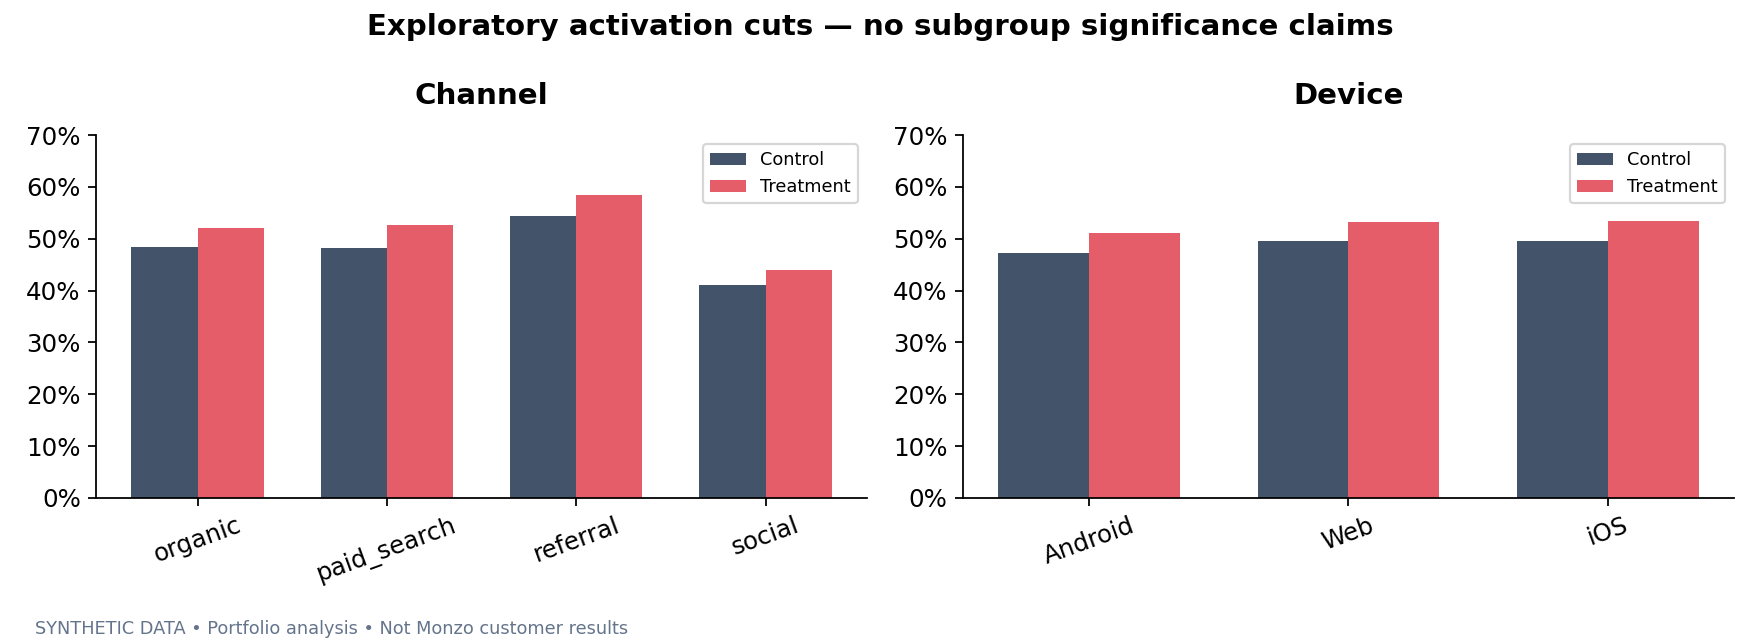

In [9]:
segments=con.execute((ROOT/'sql/06_segment_analysis.sql').read_text()).pl(); display(segments); display(Image(filename=str(ROOT/'reports/figures/05_segments.png')))

## 7. Funnel by acquisition channel
This deeper cut can identify where to ask product questions; it does not explain why a channel differs.

In [10]:
display(con.sql("""SELECT channel,variant,count(*) AS assigned,
 avg(verified_7d) AS verification_rate,avg(funded_7d) AS funding_rate,
 avg(activated_7d) AS activation_rate
 FROM user_metrics WHERE mature_7d GROUP BY ALL ORDER BY channel,variant""").pl())

channel,variant,assigned,verification_rate,funding_rate,activation_rate
str,str,i64,f64,f64,f64
"""organic""","""control""",42358,0.743921,0.585297,0.483238
"""organic""","""treatment""",42228,0.778607,0.629843,0.521218
"""paid_search""","""control""",35120,0.74029,0.585592,0.481748
"""paid_search""","""treatment""",35380,0.778321,0.634454,0.526173
"""referral""","""control""",27464,0.785865,0.656569,0.543402
"""referral""","""treatment""",27438,0.826299,0.709855,0.583607
"""social""","""control""",19960,0.681062,0.498146,0.41002
"""social""","""treatment""",20052,0.717086,0.53456,0.438909


## 8. Weekly return definition
Week 1 is days 7–13, week 2 days 14–20, and week 3 days 21–27 since assignment. Return means an app-open or successful payment. Every denominator has enough observation time.

In [11]:
retention=con.execute((ROOT/'sql/05_retention_cohorts.sql').read_text()).pl(); display(retention.head(18))

variant,signup_week,week,eligible_users,returning_users,return_rate
str,date,i64,i64,i64,f64
"""control""",2025-12-29,1,5938,5461,0.91967
"""control""",2025-12-29,2,5938,5442,0.91647
"""control""",2025-12-29,3,5938,5485,0.923712
"""control""",2026-01-05,1,10456,9604,0.918516
"""control""",2026-01-05,2,10456,9626,0.92062
"""control""",2026-01-05,3,10456,9639,0.921863
"""control""",2026-01-12,1,10223,9385,0.918028
"""control""",2026-01-12,2,10223,9390,0.918517
…,…,…,…,…,…


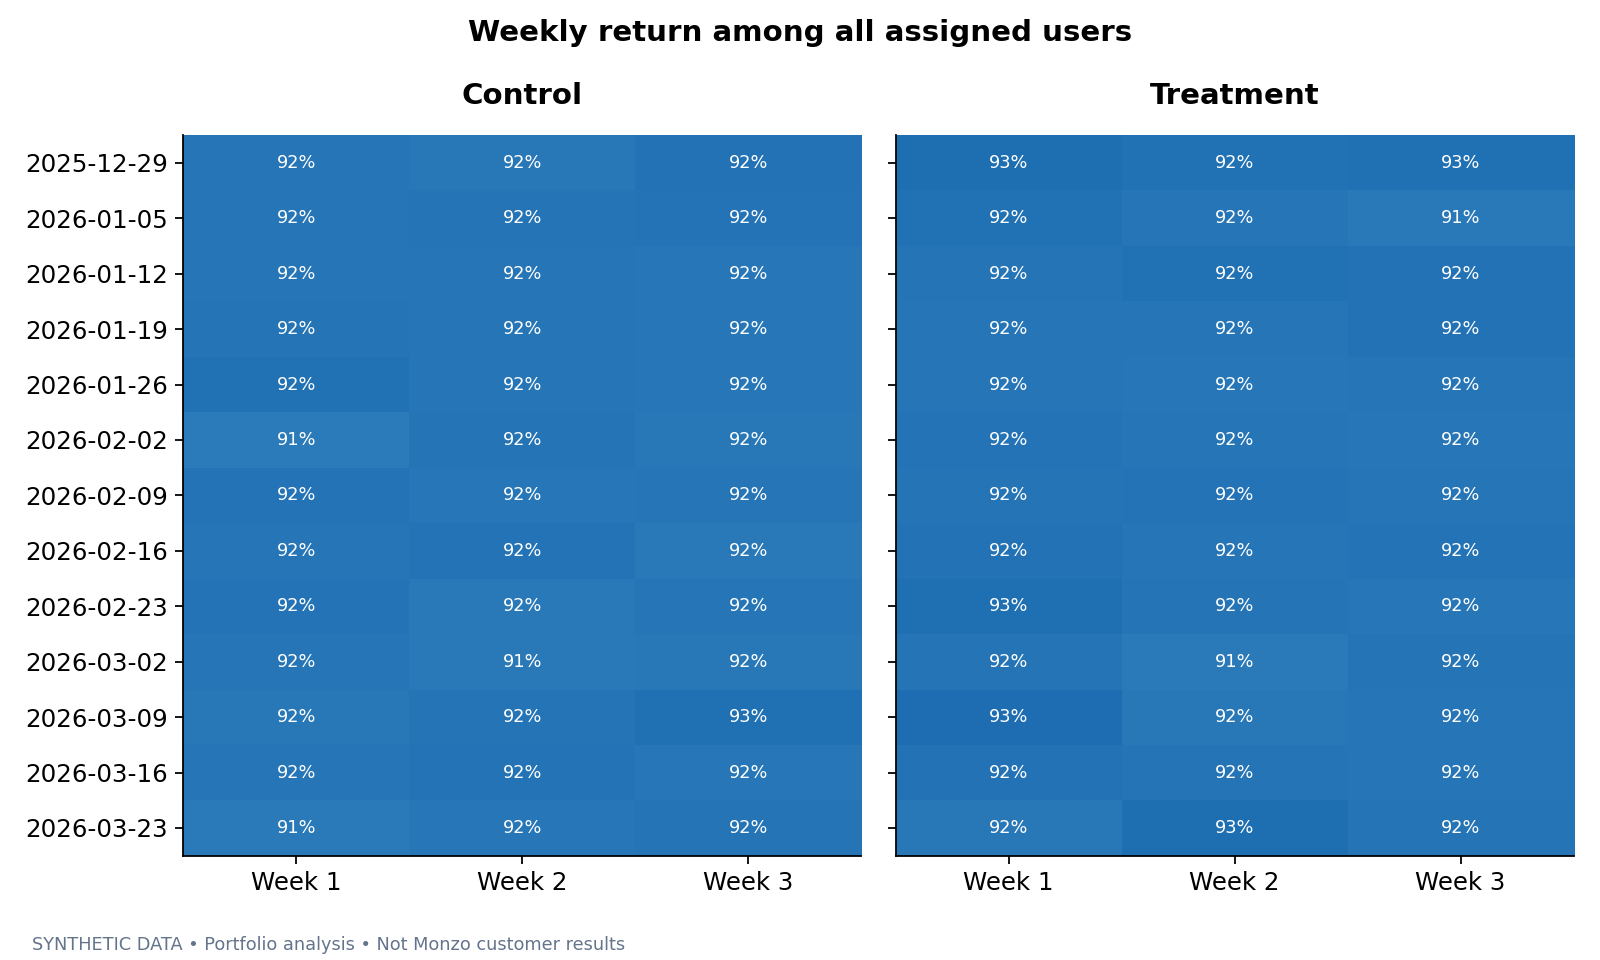

In [12]:
display(Image(filename=str(ROOT/'reports/figures/04_retention_cohorts.png')))

## 9. Weighted cohort aggregation
Use sums of returning and eligible users; averaging cohort percentages can overweight small cohorts.

In [13]:
display(retention.group_by('variant','week').agg(pl.col('returning_users').sum(),pl.col('eligible_users').sum()).with_columns((pl.col('returning_users')/pl.col('eligible_users')).alias('weighted_return_rate')).sort('variant','week'))

variant,week,returning_users,eligible_users,weighted_return_rate
str,i64,i64,i64,f64
"""control""",1,114819,124902,0.919273
"""control""",2,114786,124902,0.919009
"""control""",3,114760,124902,0.9188
"""treatment""",1,115445,125098,0.922836
"""treatment""",2,115075,125098,0.919879
"""treatment""",3,115074,125098,0.919871


## 10. Event count versus customer count
Activity is useful context, but the experimental unit remains the user.

In [14]:
display(con.sql("""SELECT p.variant,count(*) AS payment_transactions,
 count(DISTINCT t.user_id) AS unique_payers
 FROM raw_transactions t JOIN population p USING(user_id)
 WHERE t.kind='payment' AND t.status='success'
 GROUP BY p.variant""").pl())
con.close()

variant,payment_transactions,unique_payers
str,i64,i64
"""control""",254709,63830
"""treatment""",274560,68723


## Interpretation

Use the overall experiment to evaluate the treatment. Use funnel stages to understand where programmed changes appear, and segment cuts to propose further questions. Background app activity is deliberately simplified and may generate high return rates. Do not interpret these as retention benchmarks or claim a statistically established segment-specific benefit.